# Projet Big Data — Prédiction de la durée des déplacements urbains avec PySpark

**Objectif général :** On a deux objectifs complémentaires : d’abord analyser les comportements de mobilité, puis construire un modèle capable de prédire la durée d’un déplacement à partir d’informations disponibles avant ou au début du trajet.

### Problématique
> **Peut-on prédire la durée d'un déplacement urbain à partir des informations connues avant ou au début du trajet ?**

Le résultat est utile à un usager ou à un opérateur de mobilité : il permet d'estimer le temps de déplacement selon l'origine, la destination, l'heure, le motif, le jour et le moyen de transport.

### Étapes
1. Chargement et compréhension des données  
2. Contrôle de qualité  
3. Nettoyage avec PySpark  
4. Feature engineering  
5. Analyse exploratoire avec Spark  
6. Préparation MLlib  
7. Entraînement de plusieurs modèles de régression  
8. Évaluation et comparaison  
9. Analyse des axes de mobilité et résultats utiles au décideur

## 0. Remarque sur le fichier Excel

Apache Spark ne lit pas nativement les fichiers `.xlsx`.  
Le fichier Excel est donc lu **une seule fois** avec `pandas`, uniquement pour l'ingestion, puis immédiatement converti en DataFrame Spark.

**Toutes les étapes de nettoyage, transformation, analyse et Machine Learning sont ensuite réalisées avec PySpark.**



## 1. Importation des bibliothèques et initialisation de Spark

In [1]:
%pip install  seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install "pyarrow>=18"


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Nous avons installé PySpark pour le traitement distribué, OpenPyXL pour permettre la lecture du fichier Excel, et une version de pandas inférieure à 3 afin d’assurer la compatibilité avec PySpark.

In [4]:
%pip install pyspark openpyxl "pandas<3"


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession, Window #permet de démarrer et utiliser Spark(SparkSession),(window)permet de faire des calculs entre lignes appartenant à un même groupe, tout en conservant chaque ligne du DataFrame.
from pyspark.sql import functions as F #donne accès aux fonctions Spark comme col, when, avg, count, floor, pmod, concat_ws, etc.

In [8]:
import os       # Permet d'accéder aux variables d'environnement du système
import shutil   # Permet de vérifier si une commande est accessible dans le PATH
import pyspark  # Permet de localiser l'installation de PySpark
# Elle indique généralement le dossier où Spark est installé
print("SPARK_HOME      :", os.environ.get("SPARK_HOME"))


# Affiche la variable d'environnement JAVA_HOME
# Spark a besoin de Java pour fonctionner
print("JAVA_HOME       :", os.environ.get("JAVA_HOME"))

# Si Java est correctement configuré, cette ligne renvoie le chemin vers java.exe
print("java dans PATH  :", shutil.which("java"))
# Affiche le dossier dans lequel le package PySpark est installé
print("pyspark         :", os.path.dirname(pyspark.__file__))

SPARK_HOME      : /Users/assiakharbouch/Desktop/spark
JAVA_HOME       : /Library/Java/JavaVirtualMachines/temurin-17.jdk/Contents/Home
java dans PATH  : /Library/Java/JavaVirtualMachines/temurin-17.jdk/Contents/Home/bin/java
pyspark         : /opt/anaconda3/lib/python3.11/site-packages/pyspark


In [16]:
import sys
import os

# Supprimer une éventuelle ancienne variable SPARK_HOME.
# Cela permet à PySpark d'utiliser directement la version installée avec pip.
os.environ.pop("SPARK_HOME", None)

# Indiquer à Spark d'utiliser exactement le même interpréteur Python
# que celui utilisé par le notebook Jupyter.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable


# Type numérique Spark, si une conversion explicite en double est nécessaire
from pyspark.sql.types import DoubleType

# Pipeline MLlib :
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    StringIndexer,      # transforme les catégories textuelles en indices numériques
    OneHotEncoder,      # transforme les catégories en vecteurs indicateurs
    VectorAssembler,    # rassemble toutes les variables dans une colonne "features"
    StandardScaler      # permet de standardiser les variables numériques
)

# Modèles de régression étudiés dans le projet
from pyspark.ml.regression import (
    LinearRegression,        # régression linéaire
    RandomForestRegressor,   # forêt aléatoire
    GBTRegressor             # Gradient-Boosted Trees
)

# Outil permettant d'évaluer les performances des modèles avec des métriques comme RMSE, MAE et R²
from pyspark.ml.evaluation import RegressionEvaluator

spark = (
    SparkSession.builder #préparer la configuration de la session Spark
    .appName("Projet_Deplacements_Urbains")

    # Exécuter Spark localement en utilisant tous les cœurs disponibles
    .master("local[*]")

    # Créer la session Spark ou récupérer une session existante.
    .getOrCreate()
)

# Vérification de la version de Spark utilisée
print("Version Spark :", spark.version)

Version Spark : 4.2.0


In [14]:
spark.sparkContext.setLogLevel("ERROR")

## 2. Chargement de la feuille `deplacement`

In [18]:
import pandas as pd

# Chemin du fichier Excel
path = "donnees_deplacement_PSpark 2026.xlsx"
df_excel = pd.read_excel(path, sheet_name="deplacement")

print("Dimensions du fichier Excel :", df_excel.shape)
display(df_excel.head())

Dimensions du fichier Excel : (45605, 33)


,numMena,num_individu,num_Deplacement,Poids_extra,LieuDepart,Origine_StrateDepart,HeureDepart,LieuArrivee,Dextination_StrateArrivee,HeureArrivee,...,NbTrajetsClando,NbTrajetsCarRapide,NbTrajetsNN,NbTrajetsDDD,NbTrajetsTata,Moyen de transport,JourEnqueteIndi,PositMenage,Age,Sexe
0,1,1,1,122.133333,10,D01,815,8,D05,820,...,0.0,0.0,0.0,0.0,0.0,Autre,Vendredi,ChefMenage,53,Homme
1,1,1,2,122.133333,8,D05,2000,10,D01,2020,...,0.0,0.0,0.0,0.0,0.0,Moto,Vendredi,ChefMenage,53,Homme
2,1,2,1,122.133333,10,D01,610,10,D01,615,...,0.0,0.0,0.0,0.0,0.0,APied,Vendredi,FrereSoeur,30,Femme
3,1,2,2,122.133333,10,D01,1130,10,D01,1135,...,0.0,0.0,0.0,0.0,0.0,APied,Vendredi,FrereSoeur,30,Femme
4,1,2,3,122.133333,10,D01,2000,10,D01,2005,...,0.0,0.0,0.0,0.0,0.0,APied,Vendredi,FrereSoeur,30,Femme


In [20]:
# Conversion immédiate vers un DataFrame Spark.
df = spark.createDataFrame(df_excel)

print("Nombre de lignes :", df.count())
print("Nombre de colonnes :", len(df.columns))

/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:687: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
[Stage 0:>                                                          (0 + 8) / 8]

Nombre de lignes : 45605
Nombre de colonnes : 33


In [21]:
import pandas as pd
print(pd.__version__)

2.3.3


## 3. Compréhension de la structure des données

Nous vérifions le schéma Spark, les noms des variables et quelques observations avant d'effectuer tout nettoyage.

In [24]:
df.printSchema() #voir la structure du DataFrame Spark.

root
 |-- numMena: long (nullable = true)
 |-- num_individu: long (nullable = true)
 |-- num_Deplacement: long (nullable = true)
 |-- Poids_extra: double (nullable = true)
 |-- LieuDepart: long (nullable = true)
 |-- Origine_StrateDepart: string (nullable = true)
 |-- HeureDepart: long (nullable = true)
 |-- LieuArrivee: long (nullable = true)
 |-- Dextination_StrateArrivee: string (nullable = true)
 |-- HeureArrivee: long (nullable = true)
 |-- Duree (mn): long (nullable = true)
 |-- Motif: string (nullable = true)
 |-- NbTrajets: long (nullable = true)
 |-- Mode1: string (nullable = true)
 |-- Mode2: string (nullable = true)
 |-- Mode3: string (nullable = true)
 |-- Mode4: string (nullable = true)
 |-- Cout: double (nullable = true)
 |-- NbTrajetsAPied: double (nullable = true)
 |-- NbTrajetsAutre: double (nullable = true)
 |-- NbTrajetsMoto: double (nullable = true)
 |-- NbTrajetsVoiture: double (nullable = true)
 |-- NbTrajetsTaxi: double (nullable = true)
 |-- NbTrajetsClando: dou

In [26]:
print(df.columns)

['numMena', 'num_individu', 'num_Deplacement', 'Poids_extra', 'LieuDepart', 'Origine_StrateDepart', 'HeureDepart', 'LieuArrivee', 'Dextination_StrateArrivee', 'HeureArrivee', 'Duree (mn)', 'Motif', 'NbTrajets', 'Mode1', 'Mode2', 'Mode3', 'Mode4', 'Cout', 'NbTrajetsAPied', 'NbTrajetsAutre', 'NbTrajetsMoto', 'NbTrajetsVoiture', 'NbTrajetsTaxi', 'NbTrajetsClando', 'NbTrajetsCarRapide', 'NbTrajetsNN', 'NbTrajetsDDD', 'NbTrajetsTata', 'Moyen de transport', 'JourEnqueteIndi', 'PositMenage', 'Age', 'Sexe']


In [28]:
df.show(5, truncate=False) #afficher les 5 premières lignes du DataFrame Spark.affiche les valeurs en entier, sans les couper.

+-------+------------+---------------+----------------+----------+--------------------+-----------+-----------+-------------------------+------------+----------+---------------+---------+-----------------------+-----+-----+-----+----+----------------+----------------+----------------+----------------+-------------+---------------+------------------+-----------+------------+-------------+------------------+---------------+-----------+---+-----+
|numMena|num_individu|num_Deplacement|Poids_extra     |LieuDepart|Origine_StrateDepart|HeureDepart|LieuArrivee|Dextination_StrateArrivee|HeureArrivee|Duree (mn)|Motif          |NbTrajets|Mode1                  |Mode2|Mode3|Mode4|Cout|NbTrajetsAPied  |NbTrajetsAutre  |NbTrajetsMoto   |NbTrajetsVoiture|NbTrajetsTaxi|NbTrajetsClando|NbTrajetsCarRapide|NbTrajetsNN|NbTrajetsDDD|NbTrajetsTata|Moyen de transport|JourEnqueteIndi|PositMenage|Age|Sexe |
+-------+------------+---------------+----------------+----------+--------------------+-----------+-----

Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.11/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 262, in manager
  File "/opt/anaconda3/lib/python3.11/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 95, in worker
BrokenPipeError: [Errno 32] Broken pipe


## 4. Analyse de la qualité des données

Avant toute modification, nous recherchons :
- les valeurs nulles ;
- les doublons ;
- les valeurs extrêmes ou incohérentes ;
- la distribution des principales variables.

### 4.1 Valeurs manquantes

In [32]:
from pyspark.sql.types import NumericType

missing_exprs = []

# Parcourir toutes les colonnes du DataFrame
for field in df.schema.fields:
    c = field.name

    if isinstance(field.dataType, NumericType):
        # Pour les colonnes numériques : compter les NULL et les NaN
        expr = F.sum(
            (
                F.col(c).isNull() |
                F.isnan(F.col(c))
            ).cast("int")
        ).alias(c)

    else:
        # Pour les colonnes texte : compter les NULL et les chaînes "nan"
        expr = F.sum(
            (
                F.col(c).isNull() |
                (F.lower(F.trim(F.col(c))) == "nan")
            ).cast("int")
        ).alias(c)

    # Ajouter l'expression de comptage à la liste
    missing_exprs.append(expr)

# Afficher le nombre de valeurs manquantes pour chaque colonne
df.select(missing_exprs).show(vertical=True)

[Stage 4:>                                                          (0 + 8) / 8]

-RECORD 0--------------------------
 numMena                   | 0     
 num_individu              | 0     
 num_Deplacement           | 0     
 Poids_extra               | 0     
 LieuDepart                | 0     
 Origine_StrateDepart      | 0     
 HeureDepart               | 0     
 LieuArrivee               | 0     
 Dextination_StrateArrivee | 0     
 HeureArrivee              | 0     
 Duree (mn)                | 0     
 Motif                     | 0     
 NbTrajets                 | 0     
 Mode1                     | 0     
 Mode2                     | 37824 
 Mode3                     | 42440 
 Mode4                     | 45220 
 Cout                      | 11    
 NbTrajetsAPied            | 1     
 NbTrajetsAutre            | 0     
 NbTrajetsMoto             | 0     
 NbTrajetsVoiture          | 0     
 NbTrajetsTaxi             | 0     
 NbTrajetsClando           | 0     
 NbTrajetsCarRapide        | 0     
 NbTrajetsNN               | 0     
 NbTrajetsDDD              |

### Interprétation des valeurs manquantes

L'analyse met en évidence plusieurs types de valeurs manquantes dans la base.

- Les colonnes `Mode2`, `Mode3` et `Mode4` contiennent un grand nombre de valeurs manquantes. Cela est cohérent avec la structure des déplacements : tous les trajets ne nécessitent pas plusieurs modes de transport.
- La variable `Cout` contient seulement quelques valeurs manquantes.
- La variable `NbTrajetsAPied` contient également une valeur manquante.
- Les autres variables principales sont complètes.

Ces valeurs manquantes ne seront pas toutes traitées de la même manière. Les absences structurelles des colonnes `Mode2`, `Mode3` et `Mode4` seront conservées, tandis que les quelques valeurs manquantes numériques seront examinées avant le prétraitement.

**Interprétation attendue :**
- Les valeurs nulles de `Mode2`, `Mode3` et `Mode4` sont en grande partie structurelles : un déplacement peut ne comporter qu'un seul trajet.
- `Cout` et `NbTrajetsAPied` contiennent très peu de valeurs nulles.
- On ne supprime donc pas automatiquement toutes les lignes contenant un `NULL`.

### 4.2 Doublons

In [37]:
# Compter le nombre total de lignes du DataFrame
nb_total = df.count()

# Compter le nombre de lignes uniques
nb_distinct = df.distinct().count()

# Calculer le nombre de doublons exacts
nb_doublons = nb_total - nb_distinct

# Afficher les résultats
print("Nombre total de lignes :", nb_total)
print("Nombre de lignes distinctes :", nb_distinct)
print("Nombre de doublons exacts :", nb_doublons)

[Stage 10:==============>                                           (2 + 6) / 8]

Nombre total de lignes : 45605
Nombre de lignes distinctes : 45605
Nombre de doublons exacts : 0


### 4.3 Statistiques descriptives

In [40]:
# Statistiques sur les variables numériques les plus importantes
df.select(
    "Age",
    "HeureDepart",
    "HeureArrivee",
    "Duree (mn)",
    "Cout",
    "NbTrajets"
).describe().show()

+-------+------------------+------------------+------------------+------------------+-----+------------------+
|summary|               Age|       HeureDepart|      HeureArrivee|        Duree (mn)| Cout|         NbTrajets|
+-------+------------------+------------------+------------------+------------------+-----+------------------+
|  count|             45605|             45605|             45605|             45605|45605|             45605|
|   mean|30.146014691371562|1397.6312465738406|1423.3174871176407| 18.64578445345905|  NaN|1.2484595987282097|
| stddev|14.822551169066504| 478.3374700765367|477.65640374002845|25.891230217349992|  NaN|0.5994198048288646|
|    min|                11|               400|               407|                 1|  0.0|                 1|
|    max|                95|              2757|              3130|               900|  NaN|                 4|
+-------+------------------+------------------+------------------+------------------+-----+------------------+



### 4.4 Valeurs extrêmes à examiner

In [43]:
# Quantiles calculés directement avec Spark
for variable in ["Duree (mn)", "Cout", "Age"]:
    q = df.approxQuantile(variable, [0.50, 0.75, 0.90, 0.95, 0.99, 0.995], 0.001)
    print(variable, ":", q)

Duree (mn) : [10.0, 22.0, 45.0, 60.0, 115.0, 120.0]
Cout : [0.0, 0.0, 200.0, 300.0, 1500.0, 2000.0]
Age : [27.0, 39.0, 52.0, 60.0, 70.0, 73.0]


### Analyse des quantiles

Les quantiles permettent d’identifier les valeurs extrêmes.

- 99,5 % des durées sont ≤ 120 min, alors que certaines atteignent 900 min.
- 99,5 % des coûts sont ≤ 2000, ce qui rend la valeur 99999 très atypique.
- L’âge présente une distribution plus régulière.

Ces résultats justifient le traitement des valeurs extrêmes avant la modélisation.

In [46]:
# Quelques valeurs maximales pour comprendre les extrêmes
df.select("Duree (mn)").orderBy(F.desc("Duree (mn)")).show(20)
df.select("Cout").orderBy(F.desc("Cout")).show(20)

+----------+
|Duree (mn)|
+----------+
|       900|
|       840|
|       810|
|       795|
|       750|
|       600|
|       570|
|       552|
|       552|
|       552|
|       550|
|       545|
|       483|
|       480|
|       480|
|       480|
|       464|
|       455|
|       393|
|       391|
+----------+
only showing top 20 rows
+-------+
|   Cout|
+-------+
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|    NaN|
|99999.0|
|20000.0|
|20000.0|
|10000.0|
|10000.0|
|10000.0|
| 8500.0|
| 8000.0|
| 7500.0|
+-------+
only showing top 20 rows


Après l’analyse des quantiles, nous avons affiché les plus grandes valeurs de durée et de coût afin d’identifier précisément les observations extrêmes et de décider comment les traiter lors du nettoyage.

## 5. Nettoyage avec PySpark

Les règles suivantes sont volontairement explicites et conservatrices.

- suppression des doublons exacts ;
- conservation des valeurs nulles structurelles de `Mode2`, `Mode3`, `Mode4` ;
- remplacement de `Cout = 99999` par `NULL`, car cette valeur est extrêmement éloignée du reste de la distribution et doit être traitée comme valeur spéciale à vérifier ;
- exclusion, **pour le modèle de durée uniquement**, des déplacements de durée supérieure à 180 minutes. Le seuil est paramétrable et doit être justifié dans le rapport. Il permet d'éviter qu'une très petite quantité de valeurs extrêmes domine l'apprentissage ;
- conservation de l'ensemble des autres lignes valides.

> Le DataFrame brut `df` est conservé. Le DataFrame nettoyé utilisé pour le modèle s'appelle `df_clean`.

In [50]:
# Seuil maximal de durée retenu pour un déplacement
MAX_DURATION_MIN = 180

# Nettoyage du DataFrame
df_clean = (
    df

    # Supprimer les éventuels doublons exacts
    .dropDuplicates()

    # Remplacer la valeur spéciale 99999 du coût par une valeur nulle
    .withColumn(
        "Cout",
        F.when(F.col("Cout") == 99999, F.lit(None))
         .otherwise(F.col("Cout"))
    )

    # Conserver uniquement les durées valides :
    # non nulles, strictement positives et <= 180 minutes
    .filter(
        (F.col("Duree (mn)").isNotNull()) &
        (F.col("Duree (mn)") > 0) &
        (F.col("Duree (mn)") <= MAX_DURATION_MIN)
    )

    # Conserver uniquement les âges valides
    .filter(
        (F.col("Age").isNotNull()) &
        (F.col("Age") > 0)
    )
)

# Comparer la taille de la base avant et après nettoyage
print("Lignes avant nettoyage :", df.count())
print("Lignes après nettoyage :", df_clean.count())
print("Lignes retirées :", df.count() - df_clean.count())

Lignes avant nettoyage : 45605
Lignes après nettoyage : 45522
Lignes retirées : 83


### Interprétation du nettoyage

Le nettoyage a permis de construire un DataFrame `df_clean` destiné aux
analyses et à la modélisation, tout en conservant intact le DataFrame
original `df`.

Les doublons exacts sont supprimés par précaution. La valeur spéciale
`99999` de la variable `Cout` est remplacée par une valeur nulle afin
qu'elle ne soit pas interprétée comme un coût réel.

Pour le modèle de prédiction de la durée, seuls les déplacements dont la
durée est strictement positive et inférieure ou égale à 180 minutes sont
conservés. Ce seuil permet de limiter l'influence de quelques observations
extrêmes sur l'apprentissage tout en conservant la quasi-totalité des
déplacements.

Les observations présentant un âge nul ou non positif sont également
exclues.

Après nettoyage, 45 522 observations sur 45 605 sont conservées, soit
environ 99,8 % de la base. Seules 83 observations ont donc été retirées.

## 6. Feature engineering

Nous créons des variables plus pertinentes pour l'analyse et le Machine Learning.

### Variables temporelles
`HeureDepart` est codée sous forme HHMM. Certaines valeurs dépassent 2400 : elles représentent des heures après minuit dans la continuité de la journée d'enquête. Nous les ramenons sur une horloge de 24 heures avec un modulo 2400.

Nous créons :
- `HeureDepartNorm` ;
- `DepartHour` ;
- `DepartMinute` ;
- `PeriodeJournee`.

### Variables de mobilité
Nous créons également :
- `Route` = origine + destination ;
- `MemeStrate` = 1 si origine et destination sont dans la même strate.

In [54]:
# Normalisation de l'heure de départ
df_feat = (
    df_clean
    .withColumn("HeureDepartNorm", F.pmod(F.col("HeureDepart"), F.lit(2400)))# Ramener l'heure dans l'intervalle d'une journée : 0 à 2359
    .withColumn("DepartHour", F.floor(F.col("HeureDepartNorm") / 100).cast("int"))
    .withColumn("DepartMinute", F.pmod(F.col("HeureDepartNorm"), F.lit(100)).cast("int"))
)

# Vérification de la validité des minutes
invalid_time_count = df_feat.filter(
    (F.col("DepartHour") < 0) |
    (F.col("DepartHour") > 23) |
    (F.col("DepartMinute") < 0) |
    (F.col("DepartMinute") > 59)
).count()

print("Nombre d'heures de départ invalides :", invalid_time_count)

Nombre d'heures de départ invalides : 0


In [56]:
# Exemple simple de transformation d'une heure HHMM
exemple = spark.createDataFrame(
    [(730,), (815,), (1730,), (2359,)],
    ["HeureDepart"]
)

exemple = (
    exemple
    .withColumn("HeureDepartNorm", F.pmod(F.col("HeureDepart"), F.lit(2400)))
    .withColumn("DepartHour", F.floor(F.col("HeureDepartNorm") / 100).cast("int"))
    .withColumn("DepartMinute", F.pmod(F.col("HeureDepartNorm"), F.lit(100)).cast("int"))
)

exemple.show()

+-----------+---------------+----------+------------+
|HeureDepart|HeureDepartNorm|DepartHour|DepartMinute|
+-----------+---------------+----------+------------+
|        730|            730|         7|          30|
|        815|            815|         8|          15|
|       1730|           1730|        17|          30|
|       2359|           2359|        23|          59|
+-----------+---------------+----------+------------+



In [58]:
# Création des créneaux horaires et variables de mobilité
df_feat = (
    df_feat
    .withColumn(
        "PeriodeJournee",
        F.when((F.col("DepartHour") >= 5) & (F.col("DepartHour") < 9), "Pointe_matin")
         .when((F.col("DepartHour") >= 9) & (F.col("DepartHour") < 16), "Journee")
         .when((F.col("DepartHour") >= 16) & (F.col("DepartHour") < 20), "Pointe_soir")
         .otherwise("Nuit")
    )
         # Construire une variable représentant le trajet origine -> destination
    .withColumn(
        "Route",
        F.concat_ws(" -> ", F.col("Origine_StrateDepart"), F.col("Dextination_StrateArrivee"))
    )
        # Indiquer si le déplacement reste dans la même strate
    .withColumn(
        "MemeStrate",
        F.when(
            F.col("Origine_StrateDepart") == F.col("Dextination_StrateArrivee"), 1
        ).otherwise(0)
    )
)

df_feat.select(
    "HeureDepart", "HeureDepartNorm", "DepartHour",
    "DepartMinute", "PeriodeJournee", "Route", "MemeStrate"
).show(10, truncate=False)

+-----------+---------------+----------+------------+--------------+----------+----------+
|HeureDepart|HeureDepartNorm|DepartHour|DepartMinute|PeriodeJournee|Route     |MemeStrate|
+-----------+---------------+----------+------------+--------------+----------+----------+
|800        |800            |8         |0           |Pointe_matin  |D01 -> D18|0         |
|1405       |1405           |14        |5           |Journee       |D05 -> D01|0         |
|1200       |1200           |12        |0           |Journee       |D06 -> D06|1         |
|1300       |1300           |13        |0           |Journee       |D01 -> D01|1         |
|700        |700            |7         |0           |Pointe_matin  |D01 -> D16|0         |
|1730       |1730           |17        |30          |Pointe_soir   |D16 -> D01|0         |
|1515       |1515           |15        |15          |Journee       |D16 -> D16|1         |
|1800       |1800           |18        |0           |Pointe_soir   |D02 -> D02|1         |

### Interprétation du feature engineering

Les variables horaires ont été transformées afin de rendre l'information temporelle
plus exploitable par les modèles de Machine Learning.

La variable `HeureDepart` a été normalisée puis décomposée en heure et minute.
Aucune valeur horaire invalide n'a été détectée après cette transformation.

De nouvelles variables ont également été créées :

- `PeriodeJournee` : créneau horaire du déplacement ;
- `Route` : combinaison de la strate d'origine et de la strate de destination ;
- `MemeStrate` : indicateur égal à 1 lorsque le déplacement reste dans la même strate.

Ces nouvelles variables permettront de mieux représenter les caractéristiques
temporelles et spatiales des déplacements dans les étapes d'analyse et de modélisation.

## 7. Analyse exploratoire avec PySpark

Les agrégations sont réalisées avec Spark.  
Seuls les petits tableaux déjà agrégés sont convertis en pandas pour les graphiques.

### 7.1 Répartition des moyens de transport

Nous avons regroupé les déplacements par moyen de transport avec PySpark, compté leur fréquence, puis converti uniquement le tableau agrégé en pandas afin de construire un graphique de répartition.

+------------------+-----+
|Moyen de transport|count|
+------------------+-----+
|             APied|31903|
|              Tata| 3834|
|           Voiture| 1922|
|         CarRapide| 1888|
|            Clando| 1444|
|              Taxi| 1205|
|        Intermodal| 1200|
|               DDD|  599|
|             Autre|  578|
|                NN|  527|
|              Moto|  422|
+------------------+-----+



/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


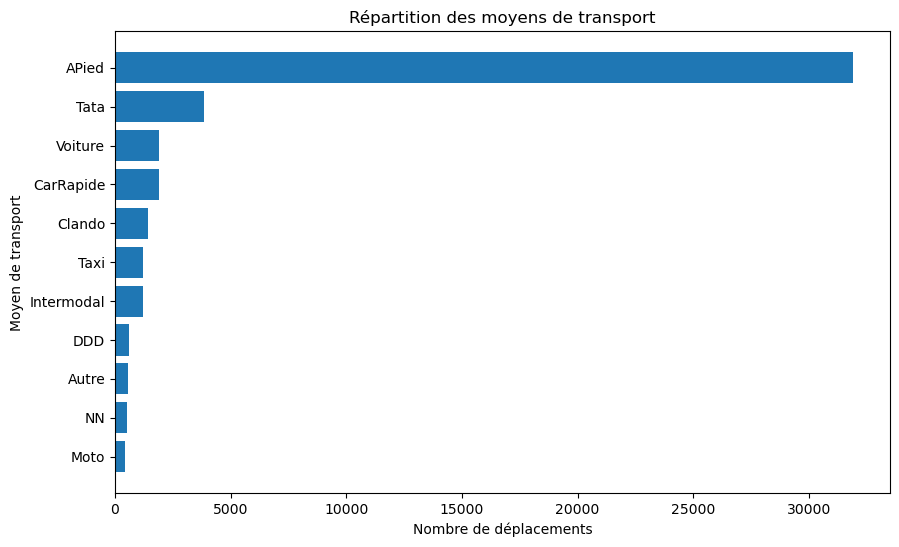

In [64]:
transport_stats = (
    df_feat
    .groupBy("Moyen de transport")
    .count()
    .orderBy(F.desc("count"))
)

transport_stats.show()

transport_pd = transport_stats.toPandas()

plt.figure(figsize=(10, 6))
plt.barh(transport_pd["Moyen de transport"], transport_pd["count"])
plt.xlabel("Nombre de déplacements")
plt.ylabel("Moyen de transport")
plt.title("Répartition des moyens de transport")
plt.gca().invert_yaxis()
plt.show()

### 7.2 Répartition des motifs

/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


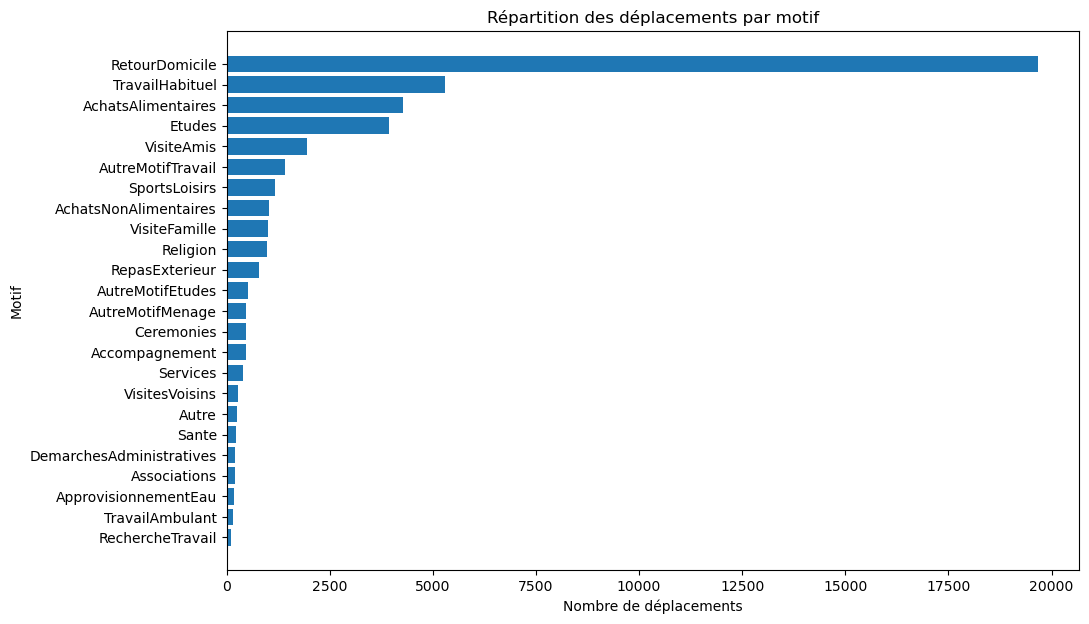

In [67]:
motif_stats = (
    df_feat
    .groupBy("Motif")
    .count()
    .orderBy(F.desc("count"))
)

motif_pd = motif_stats.toPandas()

plt.figure(figsize=(11, 7))
plt.barh(motif_pd["Motif"], motif_pd["count"])
plt.xlabel("Nombre de déplacements")
plt.ylabel("Motif")
plt.title("Répartition des déplacements par motif")
plt.gca().invert_yaxis()
plt.show()

### 7.3 Nombre de déplacements selon l'heure de départ

/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


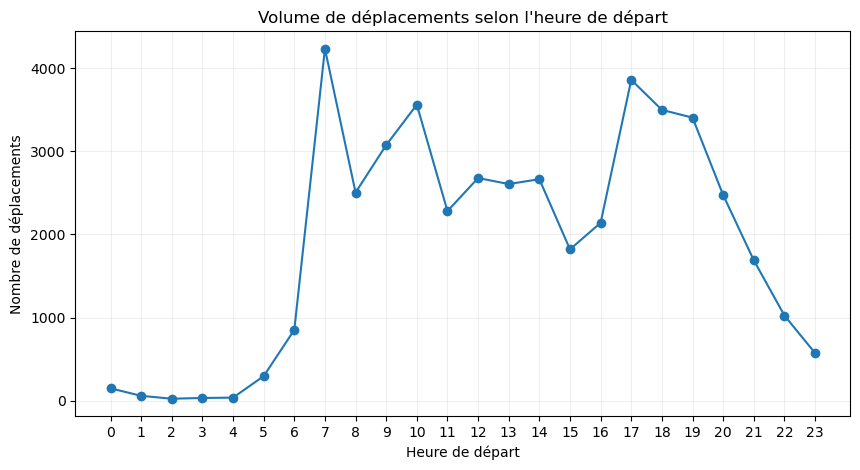

In [70]:
hour_stats = (
    df_feat
    .groupBy("DepartHour")
    .count()
    .orderBy("DepartHour")
)

hour_pd = hour_stats.toPandas()

plt.figure(figsize=(10, 5))
plt.plot(hour_pd["DepartHour"], hour_pd["count"], marker="o")
plt.xlabel("Heure de départ")
plt.ylabel("Nombre de déplacements")
plt.title("Volume de déplacements selon l'heure de départ")
plt.xticks(range(0, 24))
plt.grid(alpha=0.2)
plt.show()

### Interprétation

La distribution horaire met en évidence deux principales périodes de forte mobilité.

Un premier pic apparaît autour de 7h, ce qui correspond probablement aux
déplacements du matin, notamment vers le travail ou les études.

Un second pic est observé autour de 17h, correspondant vraisemblablement
aux déplacements de retour en fin de journée.

Entre ces deux périodes, le volume de déplacements reste important mais
plus stable. À l'inverse, les déplacements sont très faibles pendant la
nuit et augmentent progressivement à partir de 5h.

Cette structure confirme l'intérêt de la variable `PeriodeJournee`
créée précédemment, qui distingue notamment les périodes de pointe du
matin et du soir.

### 7.4 Distribution de la durée — calcul des classes avec Spark

/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


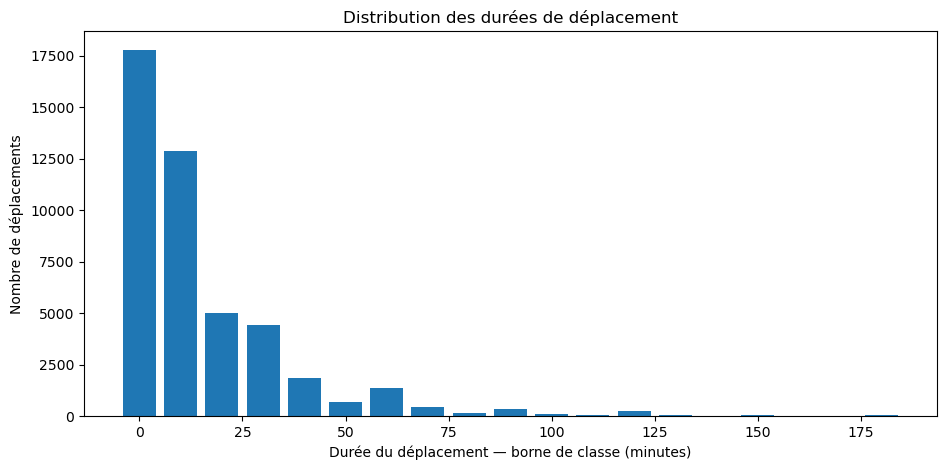

In [74]:
# Création de classes de 10 minutes avec Spark
duration_bins = (
    df_feat
    .withColumn("ClasseDuree", (F.floor(F.col("Duree (mn)") / 10) * 10).cast("int"))
    .groupBy("ClasseDuree")
    .count()
    .orderBy("ClasseDuree")
)

duration_pd = duration_bins.toPandas()

plt.figure(figsize=(11, 5))
plt.bar(duration_pd["ClasseDuree"], duration_pd["count"], width=8)
plt.xlabel("Durée du déplacement — borne de classe (minutes)")
plt.ylabel("Nombre de déplacements")
plt.title("Distribution des durées de déplacement")
plt.show()

### 7.5 Durée moyenne par moyen de transport

+------------------+------------------+------------------+
|Moyen de transport|      DureeMoyenne|NombreDeplacements|
+------------------+------------------+------------------+
|        Intermodal|63.229166666666664|              1200|
|                NN| 46.74573055028463|               527|
|               DDD| 45.14190317195325|               599|
|              Tata| 40.83098591549296|              3834|
|             Autre|  29.9878892733564|               578|
|           Voiture| 29.45369406867846|              1922|
|              Taxi| 28.87883817427386|              1205|
|         CarRapide|27.460275423728813|              1888|
|            Clando|22.477839335180054|              1444|
|              Moto| 20.62559241706161|               422|
|             APied| 10.54665705419553|             31903|
+------------------+------------------+------------------+



/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


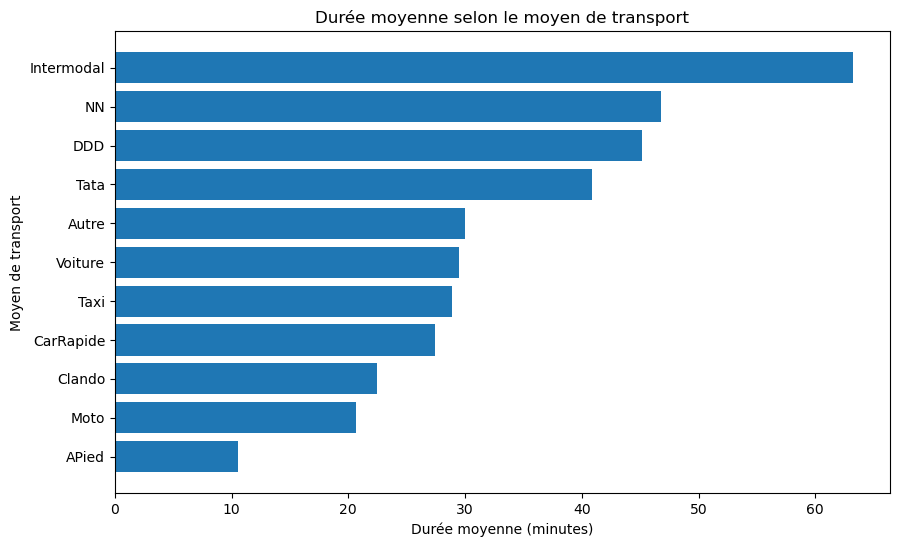

In [77]:
duration_mode = (
    df_feat
    .groupBy("Moyen de transport")
    .agg(
        F.avg("Duree (mn)").alias("DureeMoyenne"),
        F.count("*").alias("NombreDeplacements")
    )
    .orderBy(F.desc("DureeMoyenne"))
)

duration_mode.show()

duration_mode_pd = duration_mode.toPandas()

plt.figure(figsize=(10, 6))
plt.barh(duration_mode_pd["Moyen de transport"], duration_mode_pd["DureeMoyenne"])
plt.xlabel("Durée moyenne (minutes)")
plt.ylabel("Moyen de transport")
plt.title("Durée moyenne selon le moyen de transport")
plt.gca().invert_yaxis()
plt.show()

### Analyse

La durée moyenne varie fortement selon le moyen de transport. Les déplacements intermodaux sont les plus longs, avec une moyenne d’environ 63 minutes, suivis par NN et DDD.

À l’inverse, les déplacements à pied sont les plus courts, avec une durée moyenne d’environ 10,5 minutes, bien qu’ils soient largement les plus fréquents dans la base.

Cela montre que le moyen de transport est une variable importante pour expliquer la durée des déplacements.

### 7.6 Principaux flux origine–destination

+----------+------------------+------------------+
|Route     |NombreDeplacements|DureeMoyenne      |
+----------+------------------+------------------+
|P09 -> P09|2126              |11.24412041392286 |
|P08 -> P08|1560              |13.003205128205128|
|R04 -> R04|1316              |10.133738601823708|
|R07 -> R07|1294              |9.829211746522411 |
|R05 -> R05|1283              |10.5128604832424  |
|P06 -> P06|1245              |9.123694779116466 |
|R03 -> R03|1171              |7.743808710503843 |
|P04 -> P04|1099              |8.363057324840764 |
|P02 -> P02|1087              |10.025758969641215|
|R01 -> R01|1007              |13.5759682224429  |
|R08 -> R08|957               |9.832810867293626 |
|G02 -> G02|913               |8.607886089813801 |
|D16 -> D16|899               |11.75083426028921 |
|P07 -> P07|826               |8.841404358353511 |
|D06 -> D06|770               |9.77012987012987  |
+----------+------------------+------------------+



/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


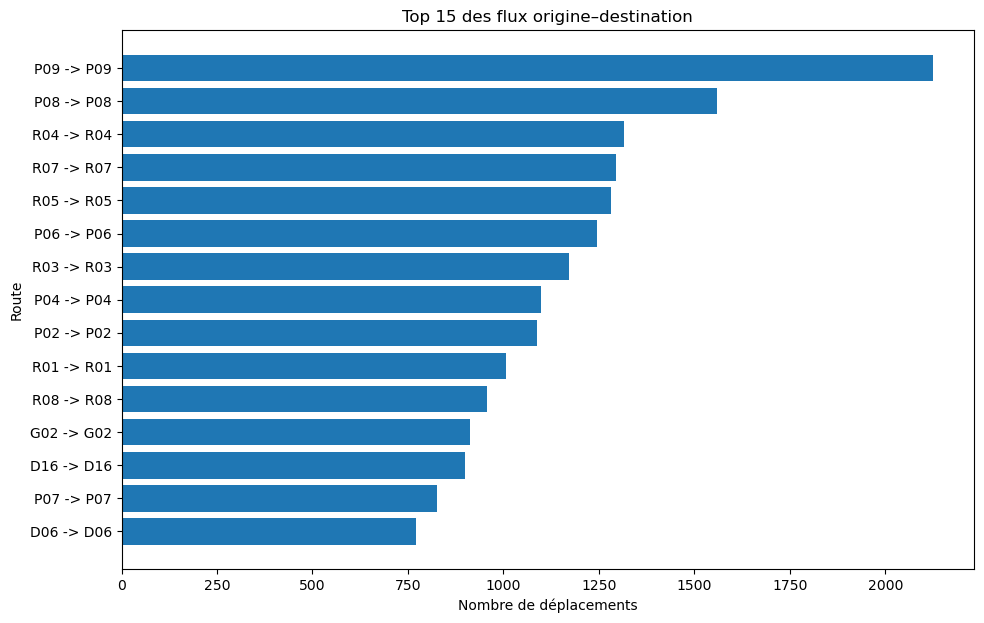

In [81]:
top_routes = (
    df_feat
    .groupBy("Route")
    .agg(
        F.count("*").alias("NombreDeplacements"),
        F.avg("Duree (mn)").alias("DureeMoyenne")
    )
    .orderBy(F.desc("NombreDeplacements"))
    .limit(15)
)

top_routes.show(truncate=False)

routes_pd = top_routes.toPandas().sort_values("NombreDeplacements")

plt.figure(figsize=(11, 7))
plt.barh(routes_pd["Route"], routes_pd["NombreDeplacements"])
plt.xlabel("Nombre de déplacements")
plt.ylabel("Route")
plt.title("Top 15 des flux origine–destination")
plt.show()

### Description des résultats

Les résultats montrent que la majorité des déplacements sont de courte durée, avec une forte concentration dans les premières classes de temps. Le nombre de déplacements diminue progressivement lorsque la durée augmente.

La durée moyenne varie également selon le moyen de transport. Les déplacements intermodaux présentent les durées moyennes les plus élevées, suivis notamment des catégories `NN`, `DDD` et `Tata`, tandis que les déplacements à pied présentent les durées moyennes les plus faibles.

Concernant les flux origine-destination, les liaisons les plus fréquentes correspondent principalement à des déplacements effectués au sein d'une même strate, comme `P09 → P09`, `P08 → P08` ou `R04 → R04`. La liaison `P09 → P09` est la plus représentée parmi les flux observés.

Enfin, l'analyse horaire fait apparaître deux périodes de forte mobilité, avec un premier pic autour de 7h et un second autour de 17h.

## 8. Définition du problème de Machine Learning

### Variable cible
La cible est :

**`Duree (mn)`**

Il s'agit donc d'un **problème de régression**.

### Variables utilisées
Nous utilisons uniquement des informations qui peuvent être connues avant ou au début du déplacement :

**Catégorielles**
- `Origine_StrateDepart`
- `Dextination_StrateArrivee`
- `Motif`
- `Moyen de transport`
- `JourEnqueteIndi`
- `Sexe`
- `PeriodeJournee`

**Numériques**
- `Age`
- `DepartHour`
- `DepartMinute`
- `MemeStrate`

### Variables volontairement exclues
- `HeureArrivee` : elle révélerait directement une partie de la durée ;
- les variables construites à partir des trajets réellement effectués (`Mode1` à `Mode4`, `NbTrajets...`) : elles ne sont pas forcément connues avant le déplacement ;
- `Cout` : il peut n'être connu qu'après le trajet ;
- les identifiants `numMena`, `num_individu`, `num_Deplacement` ;
- `Poids_extra` : poids d'enquête, pas une caractéristique prédictive individuelle.

Cette sélection limite le **data leakage**.

## 9. Préparation des données pour Spark MLlib

In [86]:
# Nom de la cible
label_col = "Duree (mn)"

categorical_cols = [
    "Origine_StrateDepart",
    "Dextination_StrateArrivee",
    "Motif",
    "Moyen de transport",
    "JourEnqueteIndi",
    "Sexe",
    "PeriodeJournee"
]

numeric_cols = [
    "Age",
    "DepartHour",
    "DepartMinute",
    "MemeStrate"
]

# Sélection uniquement des colonnes utiles
ml_df = df_feat.select(*(categorical_cols + numeric_cols + [label_col]))

# Suppression des lignes où une feature indispensable serait nulle
ml_df = ml_df.dropna(subset=categorical_cols + numeric_cols + [label_col])

print("Nombre de lignes disponibles pour le ML :", ml_df.count())

Nombre de lignes disponibles pour le ML : 45522


### 9.1 Encodage et assemblage

Les variables textuelles sont transformées avec :
1. `StringIndexer` ;
2. `OneHotEncoder`.

Toutes les variables sont ensuite rassemblées dans un vecteur `features` avec `VectorAssembler`.

In [89]:
# Indexation des variables catégorielles
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_idx",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

# One-hot encoding
encoder = OneHotEncoder(
    inputCols=[f"{c}_idx" for c in categorical_cols],
    outputCols=[f"{c}_ohe" for c in categorical_cols],
    handleInvalid="keep"
)

# Assemblage des features
assembler = VectorAssembler(
    inputCols=[f"{c}_ohe" for c in categorical_cols] + numeric_cols,
    outputCol="features",
    handleInvalid="keep"
)

Nous avons d'abord indexé les variables catégorielles avec StringIndexer, puis appliqué un one-hot encoding afin d'éviter toute relation d'ordre artificielle entre les catégories. Enfin, VectorAssembler regroupe toutes les variables catégorielles encodées et numériques dans un seul vecteur features utilisé par les modèles.

## 10. Séparation entraînement / test/validation

In [93]:
# Division des données en 3 ensembles :
# 70 % entraînement, 15 % validation, 15 % test

train_df, val_df, test_df = ml_df.randomSplit(
    [0.70, 0.15, 0.15],
    seed=42
)

print("Train      :", train_df.count())
print("Validation :", val_df.count())
print("Test       :", test_df.count())

Train      : 32101
Validation : 6694
Test       : 6727


Nous séparons les données en trois ensembles. Le jeu d’entraînement sert à apprendre les modèles, le jeu de validation sert à comparer les modèles et ajuster les hyperparamètres, et le jeu de test est conservé jusqu’à la fin pour obtenir une évaluation objective sur des données totalement nouvelles.

### Modèles de régression

Nous comparons trois modèles :

- **Régression linéaire** : modèle simple utilisé comme référence. Il suppose une relation principalement linéaire entre les variables explicatives et la durée.

- **Random Forest Regressor** : ensemble de plusieurs arbres de décision construits en parallèle. Leurs prédictions sont combinées afin d’obtenir un modèle plus robuste et capable de gérer des relations non linéaires.

- **Gradient-Boosted Trees Regressor (GBT)** : ensemble d’arbres construits séquentiellement. Chaque nouvel arbre cherche à corriger les erreurs des précédents.

### Métriques d’évaluation

Les modèles sont comparés à l’aide de :

- **RMSE** : mesure l’erreur globale et pénalise fortement les grosses erreurs. Plus elle est faible, mieux c’est.
- **MAE** : représente l’erreur absolue moyenne, exprimée ici en minutes. Plus elle est faible, mieux c’est.
- **R²** : mesure la proportion de la variabilité de la durée expliquée par le modèle. Plus il est proche de 1, mieux c’est.

Ainsi, le meilleur modèle est celui qui présente une **RMSE et une MAE faibles** ainsi qu’un **R² élevé**.

In [97]:
# Définition des modèles
models = {
    "Linear Regression": LinearRegression(
        featuresCol="features",
        labelCol=label_col,
        maxIter=100,
        regParam=0.1,
        elasticNetParam=0.0
    ),
    "Random Forest": RandomForestRegressor(
        featuresCol="features",
        labelCol=label_col,
        numTrees=100,
        maxDepth=10,
        seed=42
    ),
    "Gradient-Boosted Trees": GBTRegressor(
        featuresCol="features",
        labelCol=label_col,
        maxIter=60,
        maxDepth=7,
        seed=42
    )
}

# Evaluateurs
rmse_eval = RegressionEvaluator(
    labelCol=label_col,
    predictionCol="prediction",
    metricName="rmse"
)

mae_eval = RegressionEvaluator(
    labelCol=label_col,
    predictionCol="prediction",
    metricName="mae"
)

r2_eval = RegressionEvaluator(
    labelCol=label_col,
    predictionCol="prediction",
    metricName="r2"
)

In [99]:
# Entraînement sur le train et évaluation sur la validation
results = [] #liste vide qui va contenir les performances des modèles.
fitted_models = {} #dictionnaire vide pour conserver les modèles entraînés.
predictions_dict = {} #conserve aussi les prédictions de chaque modèle.

for name, model in models.items():
    print(f"\n===== {name} =====")

    # Pipeline complet :
    # indexation -> one-hot encoding -> assemblage -> modèle
    pipeline = Pipeline(
        stages=indexers + [encoder, assembler, model]
    )

    # Entraînement uniquement sur le jeu d'entraînement
    fitted = pipeline.fit(train_df)

    # Prédictions sur le jeu de validation
    pred = fitted.transform(val_df)

    # Calcul des métriques
    rmse = rmse_eval.evaluate(pred)
    mae = mae_eval.evaluate(pred)
    r2 = r2_eval.evaluate(pred)

    # Stockage des résultats
    results.append((name, rmse, mae, r2))
    fitted_models[name] = fitted
    predictions_dict[name] = pred

    print(f"RMSE = {rmse:.3f}")
    print(f"MAE  = {mae:.3f}")
    print(f"R²   = {r2:.3f}")


===== Linear Regression =====


RMSE = 14.783
MAE  = 9.139
R²   = 0.468

===== Random Forest =====


RMSE = 14.429
MAE  = 8.775
R²   = 0.493

===== Gradient-Boosted Trees =====
RMSE = 14.353
MAE  = 8.493
R²   = 0.499


### Analyse des performances sur le jeu de validation

Les trois modèles présentent des performances assez proches, mais les modèles basés sur les arbres donnent de meilleurs résultats que la régression linéaire.

- **Régression linéaire** : RMSE = 14,783, MAE = 9,139 et R² = 0,468.
- **Random Forest** : améliore les performances avec une RMSE de 14,429, une MAE de 8,775 et un R² de 0,493.
- **Gradient-Boosted Trees (GBT)** obtient les meilleurs résultats avec une RMSE de 14,353, une MAE de 8,493 et un R² de 0,499.

Le **GBT est donc le meilleur modèle sur le jeu de validation**, car il présente les erreurs les plus faibles et le R² le plus élevé. Il explique environ **49,9 % de la variabilité des durées de déplacement**, avec une erreur absolue moyenne d’environ **8,5 minutes**.

Il sera donc retenu pour l’évaluation finale sur le jeu de test.

In [102]:
# Récupérer le meilleur modèle choisi sur la validation
best_model = fitted_models["Gradient-Boosted Trees"]

# Faire les prédictions sur le jeu de test
test_pred = best_model.transform(test_df)

# Évaluer les performances finales
test_rmse = rmse_eval.evaluate(test_pred)
test_mae = mae_eval.evaluate(test_pred)
test_r2 = r2_eval.evaluate(test_pred)

print("===== Performance finale sur le jeu de test =====")
print(f"RMSE = {test_rmse:.3f}")
print(f"MAE  = {test_mae:.3f}")
print(f"R²   = {test_r2:.3f}")

===== Performance finale sur le jeu de test =====
RMSE = 14.858
MAE  = 8.641
R²   = 0.488


### Évaluation finale sur le jeu de test

Le modèle **Gradient-Boosted Trees (GBT)**, sélectionné à partir du jeu de validation, est ensuite évalué sur le jeu de test.

Les performances obtenues sont :

- **RMSE = 14,858**
- **MAE = 8,641**
- **R² = 0,488**

La MAE indique que le modèle se trompe en moyenne d’environ **8,6 minutes** sur la durée d’un déplacement.

Le R² de **0,488** signifie que le modèle explique environ **48,8 % de la variabilité** des durées.

Les performances sur le test restent proches de celles obtenues sur la validation, ce qui indique que le modèle généralise de manière relativement stable sur des données non utilisées lors de l’entraînement ou de la sélection.

## 12. Comparaison des modèles

In [106]:
# Création d'un petit tableau Spark contenant les performances
results_df = spark.createDataFrame(
    results,
    ["Modele", "RMSE", "MAE", "R2"]
).orderBy("RMSE")

results_df.show(truncate=False)

+----------------------+------------------+-----------------+-------------------+
|Modele                |RMSE              |MAE              |R2                 |
+----------------------+------------------+-----------------+-------------------+
|Gradient-Boosted Trees|14.353386273681556|8.493358089541962|0.49877299673850906|
|Random Forest         |14.429408339802762|8.7750709217473  |0.49344948345108197|
|Linear Regression     |14.782628193555045|9.13859488151886 |0.4683460770740129 |
+----------------------+------------------+-----------------+-------------------+



/opt/anaconda3/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


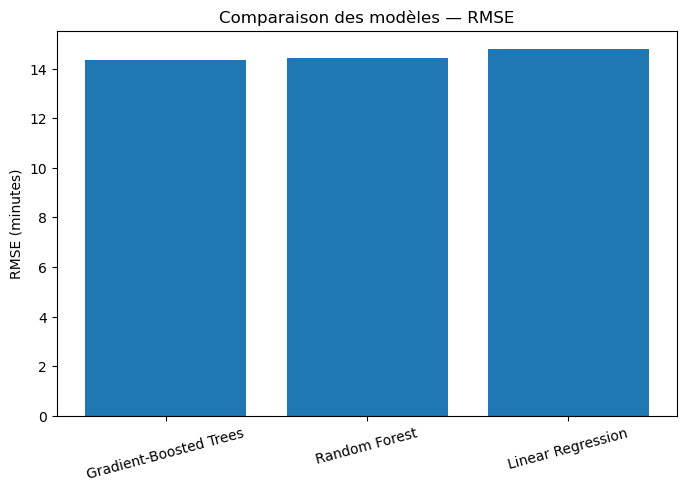

In [108]:
# Visualisation de la RMSE des modèles
results_pd = results_df.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(results_pd["Modele"], results_pd["RMSE"])
plt.ylabel("RMSE (minutes)")
plt.title("Comparaison des modèles — RMSE")
plt.xticks(rotation=15)
plt.show()

In [110]:
# Sélection automatique du meilleur modèle selon la RMSE
best_row = results_df.orderBy("RMSE").first()
best_model_name = best_row["Modele"]

print("Meilleur modèle selon la RMSE :", best_model_name)

best_model = fitted_models[best_model_name]
best_predictions = predictions_dict[best_model_name]

Meilleur modèle selon la RMSE : Gradient-Boosted Trees


## 13. Analyse des prédictions

Nous comparons quelques valeurs réelles et prédites afin de vérifier la qualité pratique du modèle.

In [113]:
best_predictions.select(
    "Origine_StrateDepart",
    "Dextination_StrateArrivee",
    "Moyen de transport",
    "DepartHour",
    "Duree (mn)",
    F.round("prediction", 2).alias("DureePredite")
).show(20, truncate=False)

+--------------------+-------------------------+------------------+----------+----------+------------+
|Origine_StrateDepart|Dextination_StrateArrivee|Moyen de transport|DepartHour|Duree (mn)|DureePredite|
+--------------------+-------------------------+------------------+----------+----------+------------+
|D01                 |D01                      |APied             |10        |5         |6.11        |
|D01                 |D01                      |Tata              |17        |20        |9.54        |
|D01                 |D01                      |APied             |7         |10        |4.83        |
|D01                 |D01                      |APied             |7         |10        |17.47       |
|D01                 |D01                      |APied             |7         |15        |15.31       |
|D01                 |D01                      |APied             |15        |10        |6.8         |
|D01                 |D01                      |APied             |14    

### Description des prédictions

Le tableau compare, pour plusieurs déplacements du jeu de test, la durée réelle
et la durée estimée par le meilleur modèle.

Les prédictions sont globalement proches des valeurs observées pour une partie
des déplacements, mais certaines erreurs restent importantes. Par exemple, pour
certains trajets courts, le modèle peut surestimer fortement la durée, alors que
pour d'autres déplacements il fournit une estimation très proche de la valeur réelle.

Cette comparaison montre que le modèle capture une partie importante de la
structure des déplacements, tout en laissant subsister des erreurs individuelles.
L'analyse suivante consiste donc à calculer l'erreur absolue pour chaque trajet afin
d'identifier les déplacements les mieux et les moins bien prédits.

## 14. Analyse de l'erreur par déplacement

Nous créons une erreur absolue en minutes :

`ErreurAbsolue = |durée réelle - durée prédite|`

Cela permet d'identifier les déplacements que le modèle estime bien ou mal et sert à regarder à quel point le modèle se trompe pour chaque trajet individuellement.

In [115]:
# Meilleur modèle sélectionné sur la validation
best_model = fitted_models["Gradient-Boosted Trees"]

# Prédictions finales sur le jeu de test
best_predictions = best_model.transform(test_df)

# Calcul de l'erreur absolue
best_predictions = best_predictions.withColumn(
    "ErreurAbsolue",
    F.abs(F.col("prediction") - F.col("Duree (mn)"))
)

# Statistiques sur les erreurs
best_predictions.select(
    F.avg("ErreurAbsolue").alias("MAE_calculee"),
    F.expr("percentile_approx(ErreurAbsolue, 0.5)").alias("Erreur_mediane"),
    F.expr("percentile_approx(ErreurAbsolue, 0.9)").alias("Erreur_P90")
).show()

+-----------------+----------------+------------------+
|     MAE_calculee|  Erreur_mediane|        Erreur_P90|
+-----------------+----------------+------------------+
|8.640680125141005|5.01911852316433|19.480099729902665|
+-----------------+----------------+------------------+



### Interprétation des erreurs de prédiction

L’analyse des erreurs sur le jeu de test permet d’évaluer plus précisément la qualité des prédictions du modèle GBT.

- **MAE = 8,64 minutes** : le modèle s’écarte en moyenne d’environ 8,6 minutes de la durée réelle.
- **Erreur médiane = 5,02 minutes** : pour 50 % des déplacements, l’erreur est inférieure ou égale à environ 5 minutes.
- **Erreur P90 = 19,48 minutes** : pour 90 % des déplacements, l’erreur ne dépasse pas environ 19,5 minutes.

Ces résultats montrent que, même si certaines prédictions peuvent présenter des écarts importants, la majorité des erreurs restent relativement modérées.

## 15. Résultat utile au décideur : axes de mobilité les plus longs

Pour que le projet ne se limite pas à une métrique ML, nous exploitons les données pour produire une information décisionnelle.

Nous recherchons les liaisons origine–destination :
- avec un volume suffisant ;
- présentant les durées moyennes les plus élevées.

Cela permet à un opérateur ou à une collectivité d'identifier des axes qui méritent une analyse approfondie.
parmi toutes les routes origine–destination, quelles sont celles qui sont suffisamment fréquentes et qui ont des durées élevées ?

La médiane est intéressante parce qu’elle est moins sensible aux valeurs extrêmes que la moyenne.

Elle sert donc à :
- repérer les routes avec des durées moyennes élevées ;
- vérifier qu’elles sont suffisamment représentées avec au moins 50 déplacements ;
- éviter de tirer une conclusion à partir de quelques cas isolés ;
- fournir une information exploitable par une collectivité ou un opérateur de transport.

In [117]:
# Analyse des routes suffisamment représentées
route_analysis = (
    df_feat
    .groupBy("Route")
    .agg(
        F.count("*").alias("NombreDeplacements"),
        F.round(F.avg("Duree (mn)"), 2).alias("DureeMoyenne"),
        F.expr("percentile_approx(`Duree (mn)`, 0.5)").alias("DureeMediane"),
        F.expr("percentile_approx(`Duree (mn)`, 0.9)").alias("DureeP90")
    )
    .filter(F.col("NombreDeplacements") >= 50) #Tu gardes uniquement les routes avec au moins 50 déplacements observés.
    .orderBy(F.desc("DureeMoyenne"))
)

route_analysis.show(20, truncate=False)

+----------+------------------+------------+------------+--------+
|Route     |NombreDeplacements|DureeMoyenne|DureeMediane|DureeP90|
+----------+------------------+------------+------------+--------+
|P09 -> P08|73                |31.3        |30          |45      |
|R06 -> R03|65                |29.8        |20          |50      |
|P08 -> P09|75                |28.91       |30          |45      |
|D06 -> D16|66                |27.08       |20          |45      |
|D16 -> D06|58                |26.83       |25          |40      |
|R06 -> R04|114               |23.59       |20          |30      |
|P02 -> P05|67                |23.57       |20          |30      |
|P05 -> P02|67                |23.57       |20          |35      |
|D16 -> D11|84                |23.44       |20          |40      |
|R03 -> R06|71                |23.42       |20          |40      |
|D14 -> D03|58                |23.38       |20          |50      |
|P06 -> P05|116               |23.33       |20          |40   

### Description des résultats

L’analyse met en évidence les axes origine–destination les plus longs parmi ceux ayant au moins **50 déplacements observés**.

- La liaison **P09 → P08** présente la durée moyenne la plus élevée, avec **31,3 minutes** pour 73 déplacements. Sa durée médiane est de 30 minutes et 90 % des trajets durent au plus 45 minutes.
- **R06 → R03** arrive ensuite avec une durée moyenne de **29,8 minutes** et un P90 de **50 minutes**, ce qui indique la présence de trajets relativement longs.
- **P08 → P09** présente également une durée élevée, avec une moyenne de **28,91 minutes**.

Globalement, ces résultats permettent d'identifier des axes suffisamment fréquentés où les temps de déplacement sont élevés. Ils peuvent ainsi constituer des **liaisons prioritaires pour une analyse plus approfondie** par un opérateur ou un décideur en mobilité.

## 16. Résultat utile à l'usager : estimation d'un temps de déplacement

Le modèle final peut être utilisé pour estimer la durée d'un futur déplacement dès que l'utilisateur renseigne :

- origine ;
- destination ;
- motif ;
- moyen de transport ;
- jour ;
- sexe ;
- âge ;
- heure de départ.

La cellule suivante fournit un exemple générique.  
**Les valeurs doivent être remplacées par des modalités réellement présentes dans la base.**

In [125]:
# Exemple de structure pour un nouveau déplacement.
# Modifier les valeurs par des catégories existantes dans le dataset.

example_rows = [
    (
        "P09",       # Origine_StrateDepart
        "P08",       # Dextination_StrateArrivee
        "RetourDomicile", # Motif
        "APied",     # Moyen de transport
        "Dimanche",  # JourEnqueteIndi
        "Homme",     # Sexe
        "Journee",   # PeriodeJournee
        30,          # Age
        14,          # DepartHour
        0,           # DepartMinute
        0            # MemeStrate
    )
]

example_schema = (
    categorical_cols + numeric_cols
)

example_df = spark.createDataFrame(example_rows, example_schema)

example_prediction = best_model.transform(example_df)

example_prediction.select(
    *categorical_cols,
    *numeric_cols,
    F.round("prediction", 2).alias("DureePrediteMinutes")
).show(truncate=False)

+--------------------+-------------------------+--------------+------------------+---------------+-----+--------------+---+----------+------------+----------+-------------------+
|Origine_StrateDepart|Dextination_StrateArrivee|Motif         |Moyen de transport|JourEnqueteIndi|Sexe |PeriodeJournee|Age|DepartHour|DepartMinute|MemeStrate|DureePrediteMinutes|
+--------------------+-------------------------+--------------+------------------+---------------+-----+--------------+---+----------+------------+----------+-------------------+
|P09                 |P08                      |RetourDomicile|APied             |Dimanche       |Homme|Journee       |30 |14        |0           |0         |23.04              |
+--------------------+-------------------------+--------------+------------------+---------------+-----+--------------+---+----------+------------+----------+-------------------+



## 17. Conclusion

Ce projet met en œuvre un pipeline complet avec PySpark :

- ingestion de la base ;
- analyse de qualité ;
- nettoyage ;
- transformation des heures ;
- création de variables ;
- analyse exploratoire ;
- préparation avec Spark MLlib ;
- comparaison de plusieurs modèles de régression ;
- évaluation avec RMSE, MAE et R² ;
- exploitation métier des résultats.

### Valeur du projet
Le modèle permet d'estimer le temps d'un déplacement à partir d'informations disponibles avant le trajet.  
En parallèle, l'analyse origine–destination permet d'identifier les axes présentant des durées importantes et pouvant nécessiter une étude de mobilité plus approfondie.

### Améliorations possibles
- intégrer des coordonnées géographiques si elles deviennent disponibles ;
- intégrer la distance réelle origine–destination ;
- tester davantage d'hyperparamètres ;
- réaliser une validation croisée ;
- construire une petite interface permettant à un utilisateur de saisir son trajet et d'obtenir une durée estimée.